# Démonstration du package `bigdata_sim` — Homework 2.7

Ce notebook montre pas à pas ce que fait le package : chargement d'un JSON Schema et des statistiques,
calcul des tailles (section 2.5) et distribution par sharding (section 2.6).

Chaque calcul fait à la main est vérifié par un `assert` : si une cellule s'exécute sans erreur,
le code donne le même résultat que le calcul manuel.

Toute la logique est dans `bigdata_sim/model.py` ; ce notebook ne fait qu'appeler le package
(pandas et matplotlib ne servent qu'à l'affichage).

In [1]:
import json
import os
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

from bigdata_sim import load_database
from bigdata_sim.model import GB, KEY_SIZE, TYPE_SIZES

dbs = {f"DB{i}": load_database(f"schema/db{i}.json", "stats.json") for i in range(1, 6)}
print("Tailles des types :", TYPE_SIZES, "| clé :", KEY_SIZE, "B")

Tailles des types : {'integer': 8, 'number': 8, 'string': 80, 'date': 20, 'longstring': 200} | clé : 12 B


## 1. La structure objet

`load_database` renvoie un objet `Database` qui contient des `Collection`, elles-mêmes composées
d'un arbre de `Field`. C'est cet objet que les opérateurs des TD suivants utiliseront.

In [2]:
db1 = dbs["DB1"]
print(db1.name)
for name, coll in db1.collections.items():
    print(f"  {name:<10} {coll.nb_docs:>15,} documents, {len(coll.fields)} champs de premier niveau")

DB1
  Product            100,000 documents, 8 champs de premier niveau
  Stock           20,000,000 documents, 4 champs de premier niveau
  Warehouse              200 documents, 3 champs de premier niveau
  OrderLine    4,000,000,000 documents, 7 champs de premier niveau
  Client          10,000,000 documents, 7 champs de premier niveau


Affichage de l'arbre de `Field` d'un document Product en **DB2** (avec le tableau `Stock` imbriqué) :

In [3]:
def print_tree(fields, indent=""):
    for i, f in enumerate(fields):
        last = i == len(fields) - 1
        branch = "└── " if last else "├── "
        kind = f.kind if f.kind != "array" else f"array of {f.item.kind}"
        print(f"{indent}{branch}{f.name:<{18 - len(indent)}}{kind}")
        children = f.children if f.kind == "object" else (f.item.children if f.kind == "array" else [])
        print_tree(children, indent + ("    " if last else "│   "))

print_tree(dbs["DB2"].collections["Product"].fields)

├── IDP               integer
├── name              string
├── price             object
│   ├── amount        number
│   ├── currency      string
│   └── vat           integer
├── brand             string
├── description       longstring
├── image_url         string
├── Categories        array of object
│   └── title         string
├── Supplier          object
│   ├── IDS           integer
│   ├── name          string
│   ├── SIRET         string
│   ├── headOffice    string
│   └── Revenue       integer
└── Stock             array of object
    ├── IDW           integer
    ├── quantity      integer
    └── location      string


## 2. Taille d'un document Product (DB1)

Règle : **taille d'une clé = 12 B + taille de sa valeur**.

| Clé | Calcul à la main | B |
|---|---|---|
| IDP | 12 + 8 | 20 |
| name | 12 + 80 | 92 |
| price | 12 + (amount 20 + currency 92 + vat 20) | 144 |
| brand | 12 + 80 | 92 |
| description | 12 + 200 | 212 |
| image_url | 12 + 80 | 92 |
| Categories | 12 + 2 × (title 12 + 80) | 196 |
| Supplier | 12 + (20 + 92 + 92 + 92 + 20) | 328 |
| **Total** | | **1 176** |

In [4]:
product = db1.collections["Product"]
df = pd.DataFrame(
    [(f.name, f.kind, db1.field_size(f, "Product")) for f in product.fields],
    columns=["clé", "type", "taille (B)"],
)
display(df)
print("Taille du document :", db1.document_size("Product"), "B")
assert db1.document_size("Product") == 1176

,clé,type,taille (B)
0,IDP,integer,20
1,name,string,92
2,price,object,144
3,brand,string,92
4,description,longstring,212
5,image_url,string,92
6,Categories,array,196
7,Supplier,object,328


Taille du document : 1176 B


## 3. Effet des imbrications

- **Tableau** : taille = 12 + longueur moyenne × taille d'un élément, avec
  longueur = nb(enfant) / nb(parent).
  Stock dans Product : 2·10⁷ / 10⁵ = **200** ; OrderLine dans Product : 4·10⁹ / 10⁵ = **40 000**.
- **Objet** : taille = 12 + taille de l'objet (relation 1-1, pas de multiplicateur).

Dans les imbrications, l'IDP redondant avec le parent a été retiré (Stock sans IDP = 132 B,
OrderLine sans IDP = 336 B).

In [5]:
cases = [
    ("DB2", "Product",   "1176 + 12 + 200 × 132",    1176 + 12 + 200 * 132),
    ("DB3", "Stock",     "132 + 12 + 1176",          132 + 12 + 1176),
    ("DB4", "OrderLine", "336 + 12 + 1176",          336 + 12 + 1176),
    ("DB5", "Product",   "1176 + 12 + 40 000 × 336", 1176 + 12 + 40_000 * 336),
]
rows = []
for db_name, coll, formula, expected in cases:
    computed = int(dbs[db_name].document_size(coll))
    assert computed == expected, (db_name, coll, computed, expected)
    rows.append((db_name, coll, formula, expected, computed))

pd.DataFrame(rows, columns=["base", "document", "calcul à la main", "attendu (B)", "code (B)"])

,base,document,calcul à la main,attendu (B),code (B)
0,DB2,Product,1176 + 12 + 200 × 132,27588,27588
1,DB3,Stock,132 + 12 + 1176,1320,1320
2,DB4,OrderLine,336 + 12 + 1176,1524,1524
3,DB5,Product,1176 + 12 + 40 000 × 336,13441188,13441188


In [6]:
# Longueurs de tableaux utilisées par le code
print("Categories       :", db1.avg_array_length("Categories", "Product"))
print("Stock in Product :", db1.avg_array_length("Stock", "Product"))
print("OL in Product    :", db1.avg_array_length("OrderLine", "Product"))

Categories       : 2
Stock in Product : 200.0
OL in Product    : 40000.0


## 4. Taille des collections et des bases (2.5.2 et 2.5.3)

In [7]:
rows = []
for db_name, db in dbs.items():
    for name, coll in db.collections.items():
        rows.append((db_name, name, int(db.document_size(name)), coll.nb_docs, db.collection_size(name) / GB))
sizes = pd.DataFrame(rows, columns=["base", "collection", "doc (B)", "nb docs", "taille (GB)"])
pd.options.display.float_format = "{:,.4f}".format
sizes

,base,collection,doc (B),nb docs,taille (GB)
0,DB1,Product,1176,100000,0.1176
1,DB1,Stock,152,20000000,3.0400
2,DB1,Warehouse,132,200,0.0000
3,DB1,OrderLine,356,4000000000,"1,424.0000"
4,DB1,Client,512,10000000,5.1200
5,DB2,Product,27588,100000,2.7588
6,DB2,Warehouse,132,200,0.0000
7,DB2,OrderLine,356,4000000000,"1,424.0000"
8,DB2,Client,512,10000000,5.1200
9,DB3,Stock,1320,20000000,26.4000


In [8]:
totals = sizes.groupby("base")["taille (GB)"].sum()
assert round(totals["DB1"], 4) == 1432.2776
totals.to_frame("taille totale (GB)")

,taille totale (GB)
base,
DB1,"1,432.2776"
DB2,"1,431.8788"
DB3,"1,455.5200"
DB4,"6,104.1600"
DB5,"1,352.2788"


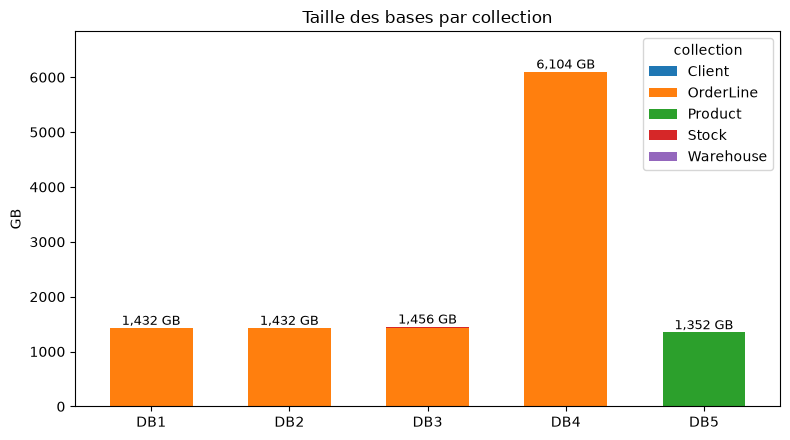

In [9]:
pivot = sizes.pivot_table(index="base", columns="collection", values="taille (GB)", fill_value=0)
ax = pivot.plot(kind="bar", stacked=True, figsize=(8, 4.5), width=0.6)
ax.set_ylabel("GB")
ax.set_ylim(0, totals.max() * 1.12)
ax.set_xlabel("")
ax.set_title("Taille des bases par collection")
ax.tick_params(axis="x", rotation=0)
for i, total in enumerate(totals):
    ax.annotate(f"{total:,.0f} GB", (i, total), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Lecture (2.5.4)**

- OrderLine (4·10⁹ documents) représente l'essentiel du volume dans toutes les bases.
- **DB4** est ~4,3× plus grosse : Product (1 176 B) est recopié dans chaque ligne de commande ;
  modifier un prix oblige à mettre à jour ~40 000 documents.
- **DB3** recopie Product dans ses 200 stocks (+23 GB).
- **DB2 et DB5** sont un peu plus petites que DB1 : imbriquer du côté « 1 » ne duplique rien,
  et l'IDP retiré de chaque élément fait gagner de la place.
- Mais en **DB5**, un document Product pèse ~13,4 MB (limite MongoDB : 16 MB) et grossit à chaque commande.

In [10]:
print(f"Document Product en DB5 : {dbs['DB5'].document_size('Product') / 1e6:.1f} MB")

Document Product en DB5 : 13.4 MB


## 5. Sharding (2.6.1)

- serveurs utilisés = min(serveurs, valeurs distinctes)
- docs par serveur = nb docs / serveurs utilisés
- valeurs distinctes par serveur = valeurs distinctes / serveurs utilisés

In [11]:
strategies = [("Stock", "IDP"), ("Stock", "IDW"), ("OrderLine", "IDC"),
              ("OrderLine", "IDP"), ("Product", "IDP"), ("Product", "brand")]
rows = []
for coll, key in strategies:
    s = db1.sharding_stats(coll, key)
    rows.append((f"{coll} - #{key}", db1.collections[coll].nb_docs, s["used_servers"],
                 s["docs_per_server"], s["distinct_per_server"]))
pd.options.display.float_format = "{:,.0f}".format
pd.DataFrame(rows, columns=["stratégie", "nb docs", "serveurs utilisés", "docs / serveur",
                            "valeurs distinctes / serveur"])

,stratégie,nb docs,serveurs utilisés,docs / serveur,valeurs distinctes / serveur
0,Stock - #IDP,20000000,1000,"20,000",100
1,Stock - #IDW,20000000,200,"100,000",1
2,OrderLine - #IDC,4000000000,1000,"4,000,000","10,000"
3,OrderLine - #IDP,4000000000,1000,"4,000,000",100
4,Product - #IDP,100000,1000,100,100
5,Product - #brand,100000,1000,100,5


Cas particulier **St - #IDW** : 200 entrepôts pour 1 000 serveurs. Une valeur de clé ne se coupe pas
entre plusieurs serveurs, donc seuls 200 serveurs reçoivent des données et 800 restent vides.

In [12]:
s = db1.sharding_stats("Stock", "IDW")
assert s == {"used_servers": 200, "docs_per_server": 100_000, "distinct_per_server": 1}
s

{'used_servers': 200, 'docs_per_server': 100000.0, 'distinct_per_server': 1.0}

La clé de sharding peut être dans un objet imbriqué (en DB4, `brand` est dans `OrderLine.Product`).
Une clé absente de la collection lève une erreur.

In [13]:
print("DB4 OL - #brand :", dbs["DB4"].sharding_stats("OrderLine", "brand"))
try:
    db1.sharding_stats("Warehouse", "IDP")
except KeyError as e:
    print("Erreur attendue :", e)

DB4 OL - #brand : {'used_servers': 1000, 'docs_per_server': 4000000.0, 'distinct_per_server': 5.0}
Erreur attendue : "La clé 'IDP' n'existe pas dans Warehouse (DB1)"


## 6. Expérience : changer les statistiques

Aucune valeur n'est codée en dur dans le package : si on passe à **400 entrepôts**, il suffit de
modifier les statistiques. Le tableau Stock de DB2 passe automatiquement de 200 à 400 éléments.

In [14]:
with open("stats.json", encoding="utf-8") as f:
    stats = json.load(f)
stats["nb_docs"]["Warehouse"] = 400
stats["nb_docs"]["Stock"] = stats["nb_docs"]["Product"] * 400
stats["distinct_values"]["IDW"] = 400

with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, "stats_400.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(stats, f)
    db1_400 = load_database("schema/db1.json", path)
    db2_400 = load_database("schema/db2.json", path)

print("Longueur du tableau Stock (DB2) :", int(db2_400.avg_array_length("Stock", "Product")))
print(f"Document Product (DB2) : {dbs['DB2'].document_size('Product'):,.0f} B -> "
      f"{db2_400.document_size('Product'):,.0f} B")
print("St - #IDW (DB1) :", db1_400.sharding_stats("Stock", "IDW"))
assert db2_400.document_size("Product") == 1176 + 12 + 400 * 132

Longueur du tableau Stock (DB2) : 400
Document Product (DB2) : 27,588 B -> 53,988 B
St - #IDW (DB1) : {'used_servers': 400, 'docs_per_server': 100000.0, 'distinct_per_server': 1.0}


## 7. Tests unitaires

La suite de tests complète (`test_bigdata_sim.py`) peut aussi être lancée depuis un terminal avec
`python -m unittest`.

In [15]:
import unittest
result = unittest.main(module="test_bigdata_sim", argv=[""], exit=False, verbosity=2).result
assert result.wasSuccessful()

test_fewer_values_than_servers (test_bigdata_sim.TestSharding.test_fewer_values_than_servers) ... 

ok


test_more_values_than_servers (test_bigdata_sim.TestSharding.test_more_values_than_servers) ... 

ok


test_nested_key (test_bigdata_sim.TestSharding.test_nested_key) ... 

...

test_nested_arrays (test_bigdata_sim.TestSizes.test_nested_arrays) ... 

ok


test_nested_objects (test_bigdata_sim.TestSizes.test_nested_objects) ... 

ok


----------------------------------------------------------------------
Ran 8 tests in 0.009s

OK
